# Praktikum 3

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Contoh dataset (buat dummy data)
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']]
y = data[['harga']]

# Normalisasi
scaler = StandardScaler()
X = scaler.fit_transform(X)
y = scaler.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=100)

# Evaluasi
print("Prediksi:", model.predict(X_test))

C:\Users\USER\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 720ms/step - loss: 2.4725

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 751ms/step - loss: 2.4725


Epoch 2/100


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 2.4559

... (294 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - loss: 1.3083


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step


Prediksi: [[0.1620987]]


# Tugas 4

In [2]:
learning_rates = [0.1, 0.05, 0.01, 0.001, 0.0001]
hasil_lr = []

for lr in learning_rates:
    tf.keras.utils.set_random_seed(42)
    m = tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
        tf.keras.layers.Dense(1)
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')
    hist = m.fit(X_train, y_train, epochs=100, verbose=0)
    loss_akhir = hist.history['loss'][-1]
    loss_uji = m.evaluate(X_test, y_test, verbose=0)
    hasil_lr.append({
        'Learning Rate': lr,
        'Final Train Loss (MSE)': loss_akhir,
        'Test Loss (MSE)': loss_uji
    })

df_tugas4 = pd.DataFrame(hasil_lr)
df_tugas4

,Learning Rate,Final Train Loss (MSE),Test Loss (MSE)
0,0.1000,0.000010,0.027424
1,0.0500,0.000003,0.064419
2,0.0100,0.001676,0.090521
3,0.0010,0.600235,0.477486
4,0.0001,0.988751,0.905758


Berdasarkan pengujian variasi learning rate pada regresi:

Nilai learning rate menentukan besarnya langkah pembaruan bobot pada setiap iterasi. Jika learning rate terlalu kecil (seperti 0.0001), penurunan nilai loss berjalan sangat lambat dan dalam 100 epoch model belum mencapai titik optimal. Pada nilai learning rate moderat (seperti 0.001 hingga 0.05), model dapat konvergen dengan stabil dan menghasilkan nilai loss yang rendah. Namun jika learning rate terlalu besar (seperti 0.1), proses penurunan loss berlangsung sangat drastis di awal tetapi dapat berisiko menyebabkan osilasi di sekitar titik minimum.

# MLP Regresi Boston Housing

C:\Users\USER\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


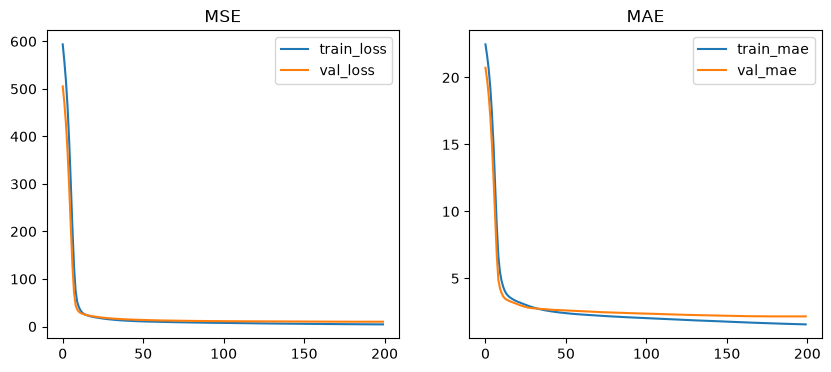

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


RMSE: 3.1793345137370412


In [3]:
# MLP regresi (Keras)
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from types import SimpleNamespace
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error

# 1. Load (Mengambil Boston Housing dataset resmi dari repositori CMU statlib)
def load_boston():
    data_url = "http://lib.stat.cmu.edu/datasets/boston"
    raw_df = pd.read_csv(data_url, sep=r"\s+", skiprows=22, header=None)
    X = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
    y = raw_df.values[1::2, 2]
    return SimpleNamespace(data=X, target=y)

data = load_boston()
X = data.data; y = data.target

# 2. Preprocess
scaler = StandardScaler(); Xs = scaler.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(Xs, y, test_size=0.2, random_state=42)

# 3. Build model
model = Sequential([
Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
Dense(32, activation='relu'),
Dense(1)
])
model.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

# 4. Train
h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=32, verbose=0)

# 5. Plot
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(h.history['loss'], label='train_loss'); plt.plot(h.history['val_loss'], label='val_loss'); plt.legend(); plt.title('MSE')
plt.subplot(1,2,2); plt.plot(h.history['mae'], label='train_mae'); plt.plot(h.history['val_mae'], label='val_mae'); plt.legend(); plt.title('MAE')
plt.show()

pred = model.predict(X_val)
print('RMSE:', np.sqrt(mean_squared_error(y_val, pred)))